<a href="https://colab.research.google.com/github/lazizbek670770/Classical-ML-and-DSA/blob/main/multirep_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Representation Diversity vs. Encoder Scaling for LLMs — Minimal Run

**Question:** Under the same trainable-parameter budget, does one large encoder or multiple smaller specialized encoders enable a frozen LLM to perform better on time-series understanding?

**Pipeline:** Synthetic time-series data → raw / FFT / statistical representations → shallow encoders → feature fusion → soft token → frozen LLM (Qwen2.5-0.5B-Instruct).

**Evaluation:** Compare trend, frequency, and anomaly classification on a held-out test dataset.

**Runs on a free Colab T4.**

In [1]:
# Questions to be asked from the LLM

# Task 1: Trend classification: increasing, decreasing, stable. (50 000 Samples)
q1 = "What is the overall trend of the time series? Choose one: increasing, decreasing, or stable."

# Task 2: Frequency classification: low, medium, high.  (50 000 Samples)
q2 = "What is the dominant frequency category of the time series? Choose one: low, medium, or high."

# Task 3: Anomaly detection: absent, spike, dip, or multiple anomalies. (50 000 Samples)
q3 = "Does the time series contain any anomalies? Choose one: absent, spike, dip, or multiple anomalies."



2. Generate the Dataset

In [2]:
import numpy as np
import json
import os
import zipfile

from scipy.stats import skew, kurtosis
import sklearn as sk
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)

OUTPUT_DIR = "/content/timeseries_dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_SAMPLES = 50_000
SEQ_LEN = 256
SAMPLING_RATE = 100  # Hz

print("Dataset configuration initialized.")




Dataset configuration initialized.


In [4]:
def generate_signal(trend_label, frequency_label, anomaly_label, rng):
    t = np.arange(SEQ_LEN) / SAMPLING_RATE

    # 1. Trend
    if trend_label == "increasing":
        slope = rng.uniform(0.015, 0.04)
    elif trend_label == "decreasing":
        slope = rng.uniform(-0.04, -0.015)
    else:
        slope = rng.uniform(-0.002, 0.002)

    trend = slope * np.arange(SEQ_LEN)

    # 2. Dominant frequency
    frequency_ranges = {
        "low": (1, 3),
        "medium": (6, 10),
        "high": (17, 25)
    }

    f_low, f_high = frequency_ranges[frequency_label]
    frequency = rng.uniform(f_low, f_high)

    amplitude = rng.uniform(0.7, 1.5)
    phase = rng.uniform(0, 2 * np.pi)

    periodic = amplitude * np.sin(
        2 * np.pi * frequency * t + phase
    )

    # Add a weaker secondary frequency
    secondary_frequency = rng.uniform(1, 25)
    secondary = 0.2 * np.sin(
        2 * np.pi * secondary_frequency * t
        + rng.uniform(0, 2 * np.pi)
    )

    # 3. Gaussian noise
    noise = rng.normal(0, 0.25, SEQ_LEN)

    signal = trend + periodic + secondary + noise

    # 4. Anomalies
    def add_spike(position, magnitude):
        width = rng.uniform(0.5, 1.5)
        signal[:] += magnitude * np.exp(
            -0.5 * ((t - t[position]) / width) ** 2
        )

    def add_dip(position, magnitude):
        width = rng.uniform(0.5, 1.5)
        signal[:] -= magnitude * np.exp(
            -0.5 * ((t - t[position]) / width) ** 2
        )

    if anomaly_label == "spike":
        position = rng.integers(20, SEQ_LEN - 20)
        add_spike(position, rng.uniform(2.5, 4.0))

    elif anomaly_label == "dip":
        position = rng.integers(20, SEQ_LEN - 20)
        add_dip(position, rng.uniform(2.5, 4.0))

    elif anomaly_label == "multiple":
        positions = rng.choice(
            np.arange(20, SEQ_LEN - 20),
            size=rng.integers(2, 4),
            replace=False
        )

        # Include at least one positive and one negative event
        add_spike(positions[0], rng.uniform(2.5, 4.0))
        add_dip(positions[1], rng.uniform(2.5, 4.0))

        for position in positions[2:]:
            if rng.random() < 0.5:
                add_spike(position, rng.uniform(2.5, 4.0))
            else:
                add_dip(position, rng.uniform(2.5, 4.0))

    return signal.astype(np.float32)


def extract_representations(signal):
    # Representation 1: Raw signal
    raw = signal.copy()

    # Representation 2: FFT magnitude
    x = np.arange(len(signal))
    coefficients = np.polyfit(x, signal, deg=1)
    detrended = signal - np.polyval(coefficients, x)

    windowed = detrended * np.hanning(len(signal))

    fft_features = np.abs(
        np.fft.rfft(windowed)
    ).astype(np.float32)

    # Representation 3: Statistical features
    stats = np.array([
        np.mean(signal),
        np.std(signal),
        np.var(signal),
        np.min(signal),
        np.max(signal),
        np.median(signal),
        coefficients[0],
        skew(signal),
        kurtosis(signal),
        np.sqrt(np.mean(signal ** 2)),
        np.mean(np.diff(np.sign(signal)) != 0)
    ], dtype=np.float32)

    return raw, fft_features, stats


def balanced_labels(n, classes, rng):
    labels = np.resize(np.array(classes), n)
    rng.shuffle(labels)
    return labels


trend_classes = [
    "increasing", "decreasing", "stable"
]

frequency_classes = [
    "low", "medium", "high"
]

anomaly_classes = [
    "absent", "spike", "dip", "multiple"
]

trend_labels = balanced_labels(
    N_SAMPLES, trend_classes, rng
)

frequency_labels = balanced_labels(
    N_SAMPLES, frequency_classes, rng
)

anomaly_labels = balanced_labels(
    N_SAMPLES, anomaly_classes, rng
)


raw_data = np.zeros(
    (N_SAMPLES, SEQ_LEN), dtype=np.float32
)

fft_data = np.zeros(
    (N_SAMPLES, SEQ_LEN // 2 + 1), dtype=np.float32
)

stats_data = np.zeros(
    (N_SAMPLES, 11), dtype=np.float32
)

for i in range(N_SAMPLES):
    signal = generate_signal(
        trend_labels[i],
        frequency_labels[i],
        anomaly_labels[i],
        rng
    )

    raw, fft, stats = extract_representations(signal)

    raw_data[i] = raw
    fft_data[i] = fft
    stats_data[i] = stats

    if (i + 1) % 5000 == 0:
        print(f"Generated {i + 1}/{N_SAMPLES}")

print("Generation completed.")

Generated 5000/50000
Generated 10000/50000
Generated 15000/50000
Generated 20000/50000
Generated 25000/50000
Generated 30000/50000
Generated 35000/50000
Generated 40000/50000
Generated 45000/50000
Generated 50000/50000
Generation completed.


In [6]:
import sklearn as sk
import numpy as np

train_test_split = sk.model_selection.train_test_split

combined_labels = np.array([
    f"{t}_{f}_{a}"
    for t, f, a in zip(
        trend_labels,
        frequency_labels,
        anomaly_labels
    )
])

indices = np.arange(N_SAMPLES)

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=combined_labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=combined_labels[temp_idx]
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 35000
Validation: 7500
Test: 7500


In [7]:
labels = {
    "trend": trend_labels,
    "frequency": frequency_labels,
    "anomaly": anomaly_labels
}

splits = {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx
}

for split_name, idx in splits.items():

    np.savez_compressed(
        f"{OUTPUT_DIR}/{split_name}.npz",

        raw=raw_data[idx],
        fft=fft_data[idx],
        stats=stats_data[idx],

        trend=trend_labels[idx],
        frequency=frequency_labels[idx],
        anomaly=anomaly_labels[idx]
    )

    print(f"Saved {split_name}.npz")

Saved train.npz
Saved validation.npz
Saved test.npz


In [8]:
import json

questions = {
    "trend": (
        "What is the overall trend of the time series? "
        "Choose one: increasing, decreasing, or stable."
    ),

    "frequency": (
        "What is the dominant frequency category of the time series? "
        "Choose one: low, medium, or high."
    ),

    "anomaly": (
        "Does the time series contain any anomalies? "
        "Choose one: absent, spike, dip, or multiple."
    )
}

# Create a lookup for each sample's split
split_lookup = np.empty(N_SAMPLES, dtype=object)

for split_name, idx in splits.items():
    split_lookup[idx] = split_name

qa_path = f"{OUTPUT_DIR}/qa_pairs.jsonl"

with open(qa_path, "w") as file:

    for i in range(N_SAMPLES):

        record = {
            "sample_id": int(i),
            "questions": questions,

            "answers": {
                "trend": str(trend_labels[i]),
                "frequency": str(frequency_labels[i]),
                "anomaly": str(anomaly_labels[i])
            },

            "split": str(split_lookup[i])
        }

        file.write(json.dumps(record) + "\n")

print("QA records saved:", qa_path)

QA records saved: /content/timeseries_dataset/qa_pairs.jsonl


In [9]:
import zipfile
import os

zip_path = "/content/timeseries_dataset.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zf:

    for filename in os.listdir(OUTPUT_DIR):
        full_path = os.path.join(OUTPUT_DIR, filename)
        zf.write(full_path, arcname=filename)

print("Dataset archive created:", zip_path)
print("Files included:", os.listdir(OUTPUT_DIR))

Dataset archive created: /content/timeseries_dataset.zip
Files included: ['train.npz', 'validation.npz', 'qa_pairs.jsonl', 'test.npz']


In [10]:
from google.colab import files

files.download("/content/timeseries_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import numpy as np
import os

splits_to_check = ["train", "validation", "test"]

for split_name in splits_to_check:

    data = np.load(
        f"{OUTPUT_DIR}/{split_name}.npz"
    )

    print(f"\n{'='*40}")
    print(f"{split_name.upper()} DATASET")
    print(f"{'='*40}")

    for key in data.files:
        arr = data[key]

        print(
            f"{key:12s} | Shape: {arr.shape}"
        )

        if arr.dtype.kind in "fc":
            print(
                f"{'':12s} | All finite: {np.isfinite(arr).all()}"
            )

    print("\nLabel distributions:")

    for task in ["trend", "frequency", "anomaly"]:
        labels, counts = np.unique(
            data[task],
            return_counts=True
        )

        print(f"\n{task}:")
        for label, count in zip(labels, counts):
            print(f"  {label}: {count}")


TRAIN DATASET
raw          | Shape: (35000, 256)
             | All finite: True
fft          | Shape: (35000, 129)
             | All finite: True
stats        | Shape: (35000, 11)
             | All finite: True
trend        | Shape: (35000,)
frequency    | Shape: (35000,)
anomaly      | Shape: (35000,)

Label distributions:

trend:
  decreasing: 11667
  increasing: 11666
  stable: 11667

frequency:
  high: 11666
  low: 11666
  medium: 11668

anomaly:
  absent: 8749
  dip: 8751
  multiple: 8750
  spike: 8750

VALIDATION DATASET
raw          | Shape: (7500, 256)
             | All finite: True
fft          | Shape: (7500, 129)
             | All finite: True
stats        | Shape: (7500, 11)
             | All finite: True
trend        | Shape: (7500,)
frequency    | Shape: (7500,)
anomaly      | Shape: (7500,)

Label distributions:

trend:
  decreasing: 2501
  increasing: 2499
  stable: 2500

frequency:
  high: 2500
  low: 2500
  medium: 2500

anomaly:
  absent: 1875
  dip: 1875
  mu

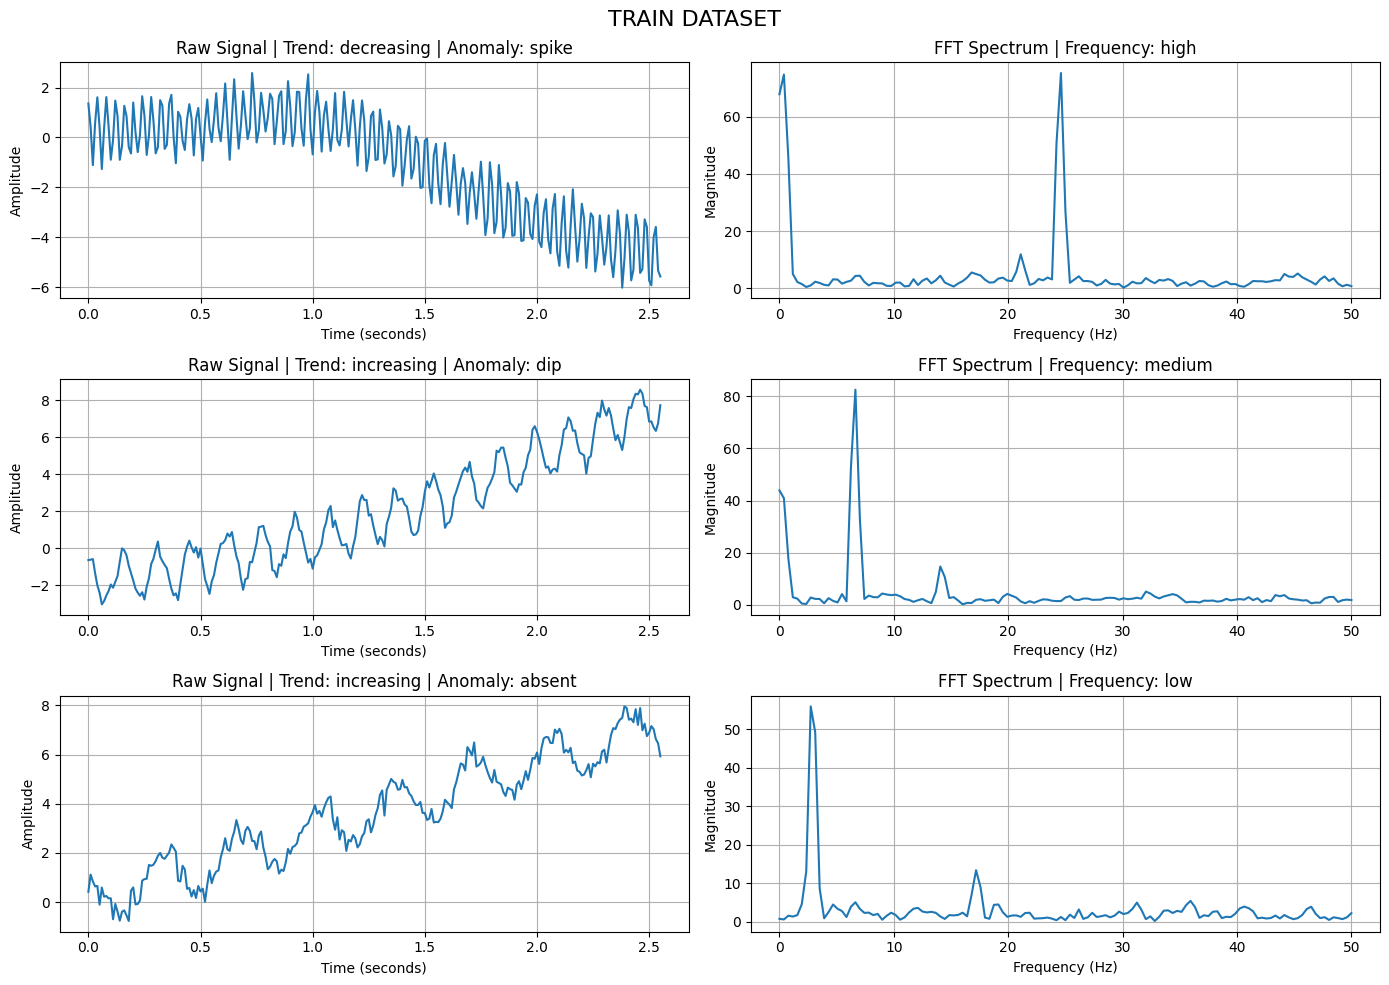

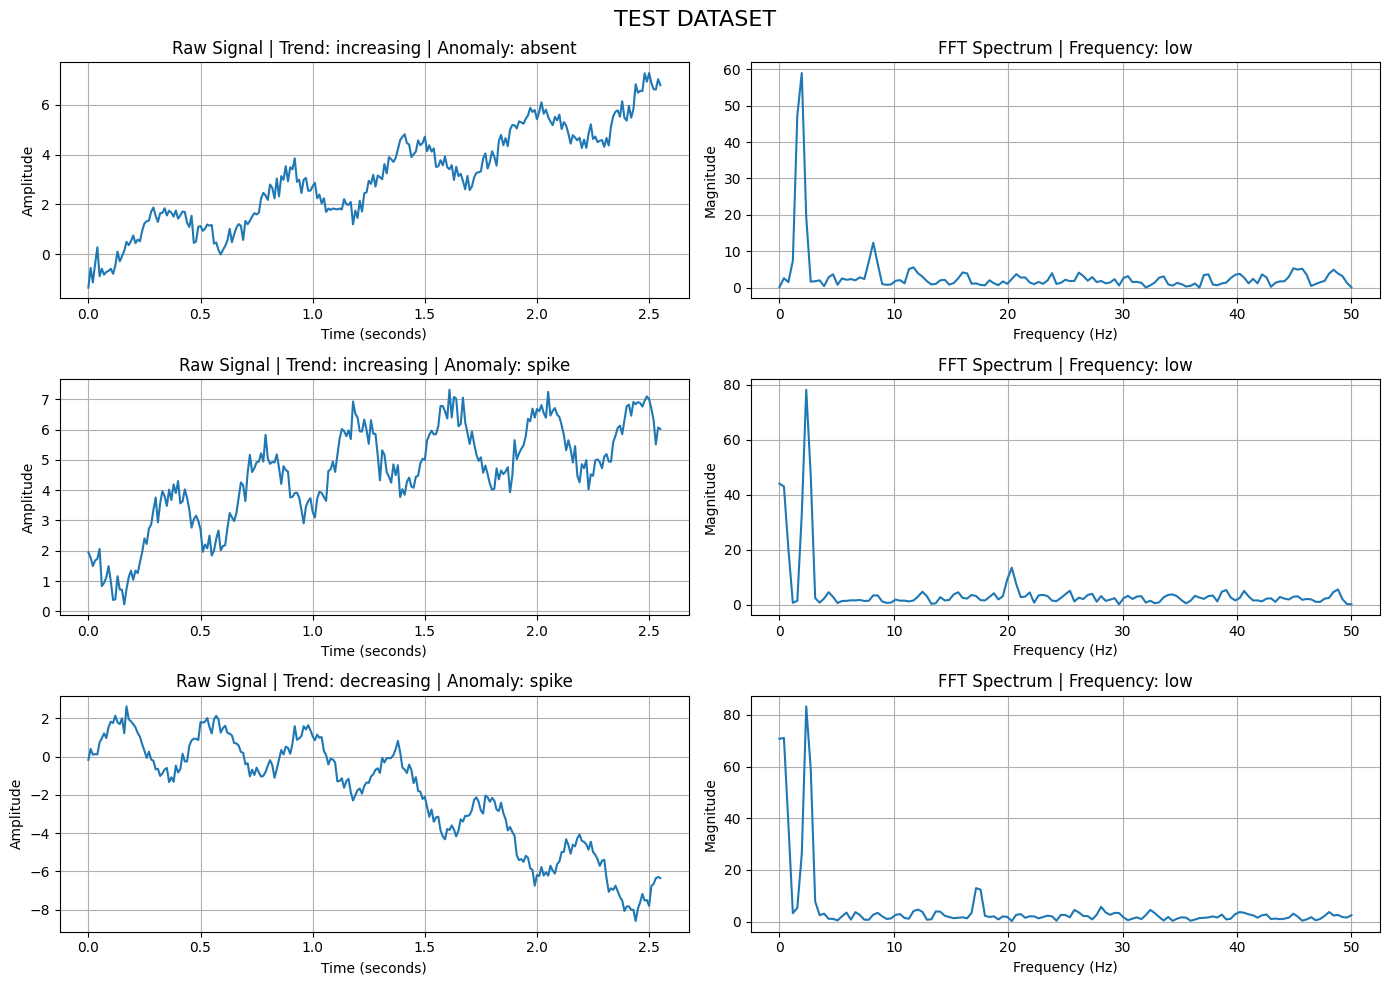

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Sampling configuration
SEQ_LEN = 256
SAMPLING_RATE = 100

time = np.arange(SEQ_LEN) / SAMPLING_RATE
frequencies = np.fft.rfftfreq(
    SEQ_LEN,
    d=1 / SAMPLING_RATE
)

# Visualize train and test
for split_name in ["train", "test"]:

    data = np.load(
        f"{OUTPUT_DIR}/{split_name}.npz"
    )

    # Select 3 random samples
    sample_indices = rng.choice(
        len(data["raw"]),
        size=3,
        replace=False
    )

    fig, axes = plt.subplots(
        3, 2,
        figsize=(14, 10)
    )

    fig.suptitle(
        f"{split_name.upper()} DATASET",
        fontsize=16
    )

    for row, idx in enumerate(sample_indices):

        raw = data["raw"][idx]
        fft = data["fft"][idx]

        trend = data["trend"][idx]
        frequency = data["frequency"][idx]
        anomaly = data["anomaly"][idx]

        # Left: Raw time series
        axes[row, 0].plot(time, raw)
        axes[row, 0].set_title(
            f"Raw Signal | Trend: {trend} | "
            f"Anomaly: {anomaly}"
        )
        axes[row, 0].set_xlabel("Time (seconds)")
        axes[row, 0].set_ylabel("Amplitude")
        axes[row, 0].grid(True)

        # Right: FFT spectrum
        axes[row, 1].plot(frequencies, fft)
        axes[row, 1].set_title(
            f"FFT Spectrum | Frequency: {frequency}"
        )
        axes[row, 1].set_xlabel("Frequency (Hz)")
        axes[row, 1].set_ylabel("Magnitude")
        axes[row, 1].grid(True)

    plt.tight_layout()
    plt.show()

In [13]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        ),
        "GB"
    )

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [14]:
!pip -q install transformers accelerate

In [15]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Load model in FP16
llm = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16
).to(device)

# Freeze all LLM parameters
for param in llm.parameters():
    param.requires_grad = False

llm.eval()

# Get embedding dimension
llm_hidden_size = llm.config.hidden_size

print("Model:", MODEL_NAME)
print("Device:", device)
print("LLM hidden size:", llm_hidden_size)
print(
    "Trainable LLM parameters:",
    sum(p.numel() for p in llm.parameters() if p.requires_grad)
)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model: Qwen/Qwen2.5-0.5B-Instruct
Device: cuda
LLM hidden size: 896
Trainable LLM parameters: 0


In [16]:
import torch
import torch.nn as nn

class TimeSeriesMLP(nn.Module):

    def __init__(self, input_dim=256, hidden_dim=512,
                 llm_dim=896):

        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),

            nn.Linear(256, hidden_dim),
            nn.ReLU()
        )

        self.projection = nn.Linear(
            hidden_dim, llm_dim
        )

    def forward(self, x):

        h = self.encoder(x)

        z = self.projection(h)

        return z

In [17]:
encoder = TimeSeriesMLP(
    input_dim=256,
    hidden_dim=512,
    llm_dim=llm_hidden_size
).to(device)

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in encoder.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Trainable parameters: 657024


In [18]:
dummy_input = torch.randn(4, 256).to(device)

with torch.no_grad():
    z = encoder(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", z.shape)

Input shape: torch.Size([4, 256])
Output shape: torch.Size([4, 896])


In [19]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

train_data = np.load(
    f"{OUTPUT_DIR}/train.npz"
)

val_data = np.load(
    f"{OUTPUT_DIR}/validation.npz"
)

test_data = np.load(
    f"{OUTPUT_DIR}/test.npz"
)

print("Datasets loaded.")

Datasets loaded.


In [20]:
train_mean = train_data["raw"].mean()
train_std = train_data["raw"].std()

print("Training mean:", train_mean)
print("Training std:", train_std)

questions = {
    "trend": (
        "What is the overall trend of the time series? "
        "Choose one: increasing, decreasing, or stable."
    ),

    "frequency": (
        "What is the dominant frequency category of the time series? "
        "Choose one: low, medium, or high."
    ),

    "anomaly": (
        "Does the time series contain any anomalies? "
        "Choose one: absent, spike, dip, or multiple."
    )
}

tasks = ["trend", "frequency", "anomaly"]




Training mean: -0.0028045108
Training std: 4.068359


In [21]:
class TimeSeriesQADataset(Dataset):

    def __init__(self, data, mean, std):

        self.raw = data["raw"]
        self.labels = {
            task: data[task]
            for task in tasks
        }

        self.mean = mean
        self.std = std

        self.samples = [
            (i, task)
            for i in range(len(self.raw))
            for task in tasks
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        sample_idx, task = self.samples[idx]

        # Normalize raw signal
        x = (
            self.raw[sample_idx] - self.mean
        ) / (self.std + 1e-8)

        x = torch.tensor(
            x, dtype=torch.float32
        )

        question = questions[task]

        answer = str(
            self.labels[task][sample_idx]
        )

        return {
            "x": x,
            "question": question,
            "answer": answer,
            "task": task
        }

In [22]:
train_dataset = TimeSeriesQADataset(
    train_data, train_mean, train_std
)

val_dataset = TimeSeriesQADataset(
    val_data, train_mean, train_std
)

test_dataset = TimeSeriesQADataset(
    test_data, train_mean, train_std
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Test examples:", len(test_dataset))

Training examples: 105000
Validation examples: 22500
Test examples: 22500


In [23]:
batch = next(iter(train_loader))

print("Signal batch shape:", batch["x"].shape)
print("First question:", batch["question"][0])
print("First answer:", batch["answer"][0])
print("First task:", batch["task"][0])

Signal batch shape: torch.Size([16, 256])
First question: What is the overall trend of the time series? Choose one: increasing, decreasing, or stable.
First answer: increasing
First task: trend


In [24]:
import torch
from torch.nn.utils.rnn import pad_sequence

def prepare_llm_batch(batch):

    x = batch["x"].to(device)

    # 1. Encode time series
    z = encoder(x)  # (B, 896)

    embedding_layer = llm.get_input_embeddings()

    input_embeddings = []
    attention_masks = []
    labels = []

    for i in range(len(x)):

        question = batch["question"][i]
        answer = batch["answer"][i]

        # 2. Format question using Qwen chat template
        prompt = tokenizer.apply_chat_template(
            [
                {
                    "role": "user",
                    "content": question
                }
            ],
            tokenize=False,
            add_generation_prompt=True
        )

        prompt_ids = tokenizer(
            prompt,
            add_special_tokens=False,
            return_tensors="pt"
        ).input_ids.to(device)

        # 3. Tokenize answer
        answer_ids = tokenizer(
            answer,
            add_special_tokens=False,
            return_tensors="pt"
        ).input_ids.to(device)

        # Append EOS
        eos = torch.tensor(
            [[tokenizer.eos_token_id]],
            device=device
        )

        answer_ids = torch.cat(
            [answer_ids, eos],
            dim=1
        )

        # 4. Convert text tokens into embeddings
        prompt_embeds = embedding_layer(prompt_ids)
        answer_embeds = embedding_layer(answer_ids)

        # 5. Combine soft token + prompt + answer
        sample_embeds = torch.cat(
            [
                z[i:i+1].unsqueeze(1).to(prompt_embeds.dtype),
                prompt_embeds,
                answer_embeds
            ],
            dim=1
        ).squeeze(0)

        # 6. Mask prompt and soft token from loss
        sample_labels = torch.cat([
            torch.full(
                (1 + prompt_ids.shape[1],),
                -100,
                dtype=torch.long,
                device=device
            ),
            answer_ids.squeeze(0)
        ])

        sample_attention = torch.ones(
            sample_embeds.shape[0],
            dtype=torch.long,
            device=device
        )

        input_embeddings.append(sample_embeds)
        labels.append(sample_labels)
        attention_masks.append(sample_attention)

    # 7. Pad sequences
    input_embeddings = pad_sequence(
        input_embeddings,
        batch_first=True,
        padding_value=0.0
    )

    labels = pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100
    )

    attention_masks = pad_sequence(
        attention_masks,
        batch_first=True,
        padding_value=0
    )

    return {
        "inputs_embeds": input_embeddings,
        "attention_mask": attention_masks,
        "labels": labels
    }

In [25]:
batch = next(iter(train_loader))

model_inputs = prepare_llm_batch(batch)

outputs = llm(
    inputs_embeds=model_inputs["inputs_embeds"],
    attention_mask=model_inputs["attention_mask"],
    labels=model_inputs["labels"],
    use_cache=False
)

print("Input embeddings:", model_inputs["inputs_embeds"].shape)
print("Attention mask:", model_inputs["attention_mask"].shape)
print("Labels:", model_inputs["labels"].shape)
print("Initial loss:", outputs.loss.item())

Input embeddings: torch.Size([16, 53, 896])
Attention mask: torch.Size([16, 53])
Labels: torch.Size([16, 53])
Initial loss: 6.9969482421875


In [26]:
# Confirm that Qwen is frozen
assert all(not p.requires_grad for p in llm.parameters())

# Make sure the MLP is trainable
for p in encoder.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(
    encoder.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Trainable parameters:", sum(
    p.numel() for p in encoder.parameters() if p.requires_grad
))

print("LLM trainable parameters:", sum(
    p.numel() for p in llm.parameters() if p.requires_grad
))

Trainable parameters: 657024
LLM trainable parameters: 0


In [27]:
# Get one batch
batch = next(iter(train_loader))

# Prepare inputs and compute loss
optimizer.zero_grad()

model_inputs = prepare_llm_batch(batch)

outputs = llm(
    inputs_embeds=model_inputs["inputs_embeds"],
    attention_mask=model_inputs["attention_mask"],
    labels=model_inputs["labels"],
    use_cache=False
)

loss = outputs.loss

# Backpropagation
loss.backward()

# Inspect gradients
grad_norm = encoder.encoder[0].weight.grad.norm().item()

print("Loss:", loss.item())
print("MLP gradient norm:", grad_norm)

# Update MLP parameters
optimizer.step()

Loss: 7.333890438079834
MLP gradient norm: 445.0184020996094


In [28]:
import time

def run_epoch(loader, training=True):
    encoder.train(training)

    total_loss = 0.0
    total_samples = 0

    for batch in loader:
        model_inputs = prepare_llm_batch(batch)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = llm(
                inputs_embeds=model_inputs["inputs_embeds"],
                attention_mask=model_inputs["attention_mask"],
                labels=model_inputs["labels"],
                use_cache=False
            )

            loss = outputs.loss

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    encoder.parameters(), max_norm=1.0
                )
                optimizer.step()

        batch_size = len(batch["x"])
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


start = time.time()

train_loss = run_epoch(train_loader, training=True)
val_loss = run_epoch(val_loader, training=False)

elapsed = time.time() - start

print(f"Training loss:   {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Time:            {elapsed / 60:.2f} minutes")

Training loss:   0.2294
Validation loss: 0.1340
Time:            20.92 minutes


In [29]:
torch.save({
    "encoder_state_dict": encoder.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 1,
    "val_loss": val_loss
}, "/content/timeseries_mlp_epoch1.pt")

print("Checkpoint saved.")

Checkpoint saved.


In [30]:
start = time.time()

train_loss = run_epoch(train_loader, training=True)
val_loss = run_epoch(val_loader, training=False)

elapsed = time.time() - start

print(f"Epoch 2")
print(f"Training loss:   {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Time:            {elapsed / 60:.2f} minutes")

Epoch 2
Training loss:   0.0828
Validation loss: 0.0771
Time:            20.96 minutes


In [31]:
start = time.time()

train_loss = run_epoch(train_loader, training=True)
val_loss = run_epoch(val_loader, training=False)

elapsed = time.time() - start

print("Epoch 3")
print(f"Training loss:   {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Time:            {elapsed / 60:.2f} minutes")

Epoch 3
Training loss:   0.0663
Validation loss: 0.0615
Time:            20.78 minutes


In [32]:
torch.save({
    "encoder_state_dict": encoder.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 3,
    "val_loss": val_loss
}, "/content/timeseries_mlp_epoch3.pt")

print("Epoch 3 checkpoint saved.")

Epoch 3 checkpoint saved.


In [33]:
candidate_answers = {
    "trend": ["increasing", "decreasing", "stable"],
    "frequency": ["low", "medium", "high"],
    "anomaly": ["absent", "spike", "dip", "multiple"]
}

print(candidate_answers)

{'trend': ['increasing', 'decreasing', 'stable'], 'frequency': ['low', 'medium', 'high'], 'anomaly': ['absent', 'spike', 'dip', 'multiple']}


In [34]:
for task, candidates in candidate_answers.items():
    print(f"\n{task.upper()}")

    for answer in candidates:
        tokens = tokenizer.encode(answer, add_special_tokens=False)
        print(f"{answer:12s} -> {tokens} (length={len(tokens)})")


TREND
increasing   -> [42742, 4422] (length=2)
decreasing   -> [450, 75462] (length=2)
stable       -> [27992] (length=1)

FREQUENCY
low          -> [10303] (length=1)
medium       -> [26086] (length=1)
high         -> [11892] (length=1)

ANOMALY
absent       -> [3435, 306] (length=2)
spike        -> [2154, 2970] (length=2)
dip          -> [67, 573] (length=2)
multiple     -> [35673] (length=1)


In [35]:
import torch
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence

encoder.eval()
llm.eval()

def score_candidates(x, task):
    candidates = candidate_answers[task]

    with torch.no_grad():
        # Encode time series
        x = x.to(device)
        z = encoder(x)

        # Construct the same prompt used during training
        prompt = tokenizer.apply_chat_template(
            [{"role": "user", "content": questions[task]}],
            tokenize=False,
            add_generation_prompt=True
        )

        prompt_ids = tokenizer(
            prompt,
            add_special_tokens=False,
            return_tensors="pt"
        ).input_ids.to(device)

        embedding_layer = llm.get_input_embeddings()
        prompt_embeds = embedding_layer(prompt_ids).squeeze(0)

        prefix_len = 1 + prompt_ids.shape[1]

        sequences = []
        target_ids = []

        for i in range(len(x)):
            for answer in candidates:
                ids = tokenizer.encode(
                    answer,
                    add_special_tokens=False
                ) + [tokenizer.eos_token_id]

                ids = torch.tensor(ids, device=device)

                answer_embeds = embedding_layer(ids)

                sequence = torch.cat([
                    z[i].unsqueeze(0).to(prompt_embeds.dtype),
                    prompt_embeds,
                    answer_embeds
                ], dim=0)

                sequences.append(sequence)
                target_ids.append(ids)

        # Pad sequences
        inputs_embeds = pad_sequence(
            sequences,
            batch_first=True,
            padding_value=0.0
        )

        attention_mask = torch.zeros(
            inputs_embeds.shape[:2],
            dtype=torch.long,
            device=device
        )

        for i, seq in enumerate(sequences):
            attention_mask[i, :len(seq)] = 1

        # Forward pass
        outputs = llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            use_cache=False
        )

        log_probs = F.log_softmax(
            outputs.logits.float(), dim=-1
        )

        scores = []

        for i, ids in enumerate(target_ids):
            positions = prefix_len - 1 + torch.arange(
                len(ids), device=device
            )

            token_scores = log_probs[i, positions, ids]

            # Average log-probability across answer tokens
            scores.append(token_scores.mean())

        scores = torch.stack(scores).reshape(
            len(x), len(candidates)
        )

        predictions = scores.argmax(dim=1)

        return scores, predictions

In [36]:
x = torch.tensor(
    (test_data["raw"][0] - train_mean) / (train_std + 1e-8),
    dtype=torch.float32
).unsqueeze(0)

for task in tasks:
    scores, predictions = score_candidates(x, task)

    print(f"\n{task.upper()}")
    for candidate, score in zip(
        candidate_answers[task], scores[0]
    ):
        print(f"{candidate:12s}: {score.item():.4f}")

    print("Prediction:", candidate_answers[task][predictions.item()])
    print("Actual:", test_data[task][0])


TREND
increasing  : -2.9589
decreasing  : -0.0005
stable      : -4.8444
Prediction: decreasing
Actual: decreasing

FREQUENCY
low         : -3.4617
medium      : -4.7117
high        : -0.0008
Prediction: high
Actual: high

ANOMALY
absent      : -0.0025
spike       : -2.5967
dip         : -4.0008
multiple    : -2.6521
Prediction: absent
Actual: absent


In [37]:
import numpy as np
from collections import defaultdict

encoder.eval()
llm.eval()

BATCH_SIZE_EVAL = 16

results = {}

for task in tasks:
    correct = 0
    total = 0

    class_correct = defaultdict(int)
    class_total = defaultdict(int)

    for start in range(0, len(test_data["raw"]), BATCH_SIZE_EVAL):

        end = min(start + BATCH_SIZE_EVAL, len(test_data["raw"]))

        # Normalize signals using training statistics
        x = (
            test_data["raw"][start:end] - train_mean
        ) / (train_std + 1e-8)

        x = torch.tensor(x, dtype=torch.float32)

        # Predict candidate answers
        scores, predictions = score_candidates(x, task)

        predictions = predictions.cpu().numpy()

        actual = test_data[task][start:end]

        candidates = candidate_answers[task]

        predicted_labels = [
            candidates[p] for p in predictions
        ]

        for pred, true in zip(predicted_labels, actual):
            total += 1
            class_total[true] += 1

            if pred == true:
                correct += 1
                class_correct[true] += 1

    accuracy = correct / total

    results[task] = accuracy

    print(f"\n{task.upper()}")
    print(f"Accuracy: {accuracy * 100:.2f}%")

    for label in candidate_answers[task]:
        class_acc = (
            class_correct[label] / class_total[label]
            if class_total[label] > 0 else 0
        )
        print(f"  {label:12s}: {class_acc * 100:.2f}%")

print("\nOVERALL ACCURACY")
print(f"{np.mean(list(results.values())) * 100:.2f}%")


TREND
Accuracy: 97.95%
  increasing  : 99.28%
  decreasing  : 98.28%
  stable      : 96.28%

FREQUENCY
Accuracy: 98.39%
  low         : 99.08%
  medium      : 97.64%
  high        : 98.44%

ANOMALY
Accuracy: 86.51%
  absent      : 96.43%
  spike       : 97.65%
  dip         : 93.38%
  multiple    : 58.56%

OVERALL ACCURACY
94.28%


In [38]:
# Calculate normalization statistics using training data only

fft_mean = train_data["fft"].mean(axis=0)
fft_std = train_data["fft"].std(axis=0)

stats_mean = train_data["stats"].mean(axis=0)
stats_std = train_data["stats"].std(axis=0)


class MultiRepQADataset(Dataset):
    def __init__(self, data):
        self.raw = data["raw"]
        self.fft = data["fft"]
        self.stats = data["stats"]

        self.labels = {
            task: data[task] for task in tasks
        }

        self.samples = [
            (i, task)
            for i in range(len(self.raw))
            for task in tasks
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample_idx, task = self.samples[idx]

        raw = (
            self.raw[sample_idx] - train_mean
        ) / (train_std + 1e-8)

        fft = (
            self.fft[sample_idx] - fft_mean
        ) / (fft_std + 1e-8)

        stats = (
            self.stats[sample_idx] - stats_mean
        ) / (stats_std + 1e-8)

        return {
            "raw": torch.tensor(raw, dtype=torch.float32),
            "fft": torch.tensor(fft, dtype=torch.float32),
            "stats": torch.tensor(stats, dtype=torch.float32),
            "question": questions[task],
            "answer": str(self.labels[task][sample_idx]),
            "task": task
        }


train_multi_dataset = MultiRepQADataset(train_data)
val_multi_dataset = MultiRepQADataset(val_data)
test_multi_dataset = MultiRepQADataset(test_data)

train_multi_loader = DataLoader(
    train_multi_dataset,
    batch_size=16,
    shuffle=True
)

val_multi_loader = DataLoader(
    val_multi_dataset,
    batch_size=16,
    shuffle=False
)

test_multi_loader = DataLoader(
    test_multi_dataset,
    batch_size=16,
    shuffle=False
)

# Inspect one batch
batch = next(iter(train_multi_loader))

print("Raw:", batch["raw"].shape)
print("FFT:", batch["fft"].shape)
print("Stats:", batch["stats"].shape)
print("Answer:", batch["answer"][0])

Raw: torch.Size([16, 256])
FFT: torch.Size([16, 129])
Stats: torch.Size([16, 11])
Answer: high


In [41]:
class MultiEncoder(nn.Module):
    def __init__(self, llm_dim=896):
        super().__init__()

        self.raw_encoder = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 167),
            nn.ReLU()
        )

        self.fft_encoder = nn.Sequential(
            nn.Linear(129, 256),
            nn.ReLU(),
            nn.Linear(256, 167),
            nn.ReLU()
        )

        self.stats_encoder = nn.Sequential(
            nn.Linear(11, 128),
            nn.ReLU(),
            nn.Linear(128, 167),
            nn.ReLU()
        )

        self.fusion = nn.Linear(501, llm_dim)

    def forward(self, raw, fft, stats):
        h_raw = self.raw_encoder(raw)
        h_fft = self.fft_encoder(fft)
        h_stats = self.stats_encoder(stats)

        combined = torch.cat(
            [h_raw, h_fft, h_stats], dim=-1
        )

        return self.fusion(combined)


multi_encoder = MultiEncoder(
    llm_dim=llm_hidden_size
).to(device)

multi_params = sum(
    p.numel() for p in multi_encoder.parameters()
    if p.requires_grad
)

print("Multi-encoder parameters:", multi_params)
print("Single-encoder parameters:", 657024)
print("Difference:", abs(multi_params - 657024))

Multi-encoder parameters: 657781
Single-encoder parameters: 657024
Difference: 757


In [42]:
multi_params = sum(
    p.numel()
    for p in multi_encoder.parameters()
    if p.requires_grad
)

print("Multi-encoder parameters:", multi_params)
print("Single-encoder parameters:", 657024)

Multi-encoder parameters: 657781
Single-encoder parameters: 657024


In [43]:
def prepare_multi_llm_batch(batch):
    raw = batch["raw"].to(device)
    fft = batch["fft"].to(device)
    stats = batch["stats"].to(device)

    z = multi_encoder(raw, fft, stats)

    embedding_layer = llm.get_input_embeddings()

    input_embeddings = []
    attention_masks = []
    labels = []

    for i in range(len(raw)):
        question = batch["question"][i]
        answer = batch["answer"][i]

        prompt = tokenizer.apply_chat_template(
            [{"role": "user", "content": question}],
            tokenize=False,
            add_generation_prompt=True
        )

        prompt_ids = tokenizer(
            prompt,
            add_special_tokens=False,
            return_tensors="pt"
        ).input_ids.to(device)

        answer_ids = tokenizer(
            answer,
            add_special_tokens=False,
            return_tensors="pt"
        ).input_ids.to(device)

        eos = torch.tensor(
            [[tokenizer.eos_token_id]],
            device=device
        )

        answer_ids = torch.cat([answer_ids, eos], dim=1)

        prompt_embeds = embedding_layer(prompt_ids)
        answer_embeds = embedding_layer(answer_ids)

        sample_embeds = torch.cat([
            z[i:i+1].unsqueeze(1).to(prompt_embeds.dtype),
            prompt_embeds,
            answer_embeds
        ], dim=1).squeeze(0)

        sample_labels = torch.cat([
            torch.full(
                (1 + prompt_ids.shape[1],),
                -100,
                dtype=torch.long,
                device=device
            ),
            answer_ids.squeeze(0)
        ])

        sample_attention = torch.ones(
            sample_embeds.shape[0],
            dtype=torch.long,
            device=device
        )

        input_embeddings.append(sample_embeds)
        labels.append(sample_labels)
        attention_masks.append(sample_attention)

    return {
        "inputs_embeds": pad_sequence(
            input_embeddings,
            batch_first=True,
            padding_value=0.0
        ),
        "attention_mask": pad_sequence(
            attention_masks,
            batch_first=True,
            padding_value=0
        ),
        "labels": pad_sequence(
            labels,
            batch_first=True,
            padding_value=-100
        )
    }

In [44]:
batch = next(iter(train_multi_loader))

model_inputs = prepare_multi_llm_batch(batch)

outputs = llm(
    inputs_embeds=model_inputs["inputs_embeds"],
    attention_mask=model_inputs["attention_mask"],
    labels=model_inputs["labels"],
    use_cache=False
)

print("Input embeddings:", model_inputs["inputs_embeds"].shape)
print("Initial loss:", outputs.loss.item())

Input embeddings: torch.Size([16, 53, 896])
Initial loss: 3.8526692390441895


In [45]:
optimizer_multi = torch.optim.AdamW(
    multi_encoder.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Trainable parameters:", sum(
    p.numel() for p in multi_encoder.parameters()
    if p.requires_grad
))

print("LLM trainable parameters:", sum(
    p.numel() for p in llm.parameters()
    if p.requires_grad
))

Trainable parameters: 657781
LLM trainable parameters: 0


In [46]:
batch = next(iter(train_multi_loader))

optimizer_multi.zero_grad()

model_inputs = prepare_multi_llm_batch(batch)

outputs = llm(
    inputs_embeds=model_inputs["inputs_embeds"],
    attention_mask=model_inputs["attention_mask"],
    labels=model_inputs["labels"],
    use_cache=False
)

loss = outputs.loss
loss.backward()

print("Loss:", loss.item())

print("Raw encoder gradient:",
      multi_encoder.raw_encoder[0].weight.grad.norm().item())

print("FFT encoder gradient:",
      multi_encoder.fft_encoder[0].weight.grad.norm().item())

print("Stats encoder gradient:",
      multi_encoder.stats_encoder[0].weight.grad.norm().item())

print("Fusion gradient:",
      multi_encoder.fusion.weight.grad.norm().item())

optimizer_multi.step()

Loss: 4.189423561096191
Raw encoder gradient: 8.789986610412598
FFT encoder gradient: 9.584190368652344
Stats encoder gradient: 1.414271354675293
Fusion gradient: 26.241613388061523


In [47]:
def run_multi_epoch(loader, training=True):
    multi_encoder.train(training)

    total_loss = 0.0
    total_samples = 0

    for batch in loader:
        model_inputs = prepare_multi_llm_batch(batch)

        if training:
            optimizer_multi.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = llm(
                inputs_embeds=model_inputs["inputs_embeds"],
                attention_mask=model_inputs["attention_mask"],
                labels=model_inputs["labels"],
                use_cache=False
            )

            loss = outputs.loss

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    multi_encoder.parameters(),
                    max_norm=1.0
                )

                optimizer_multi.step()

        batch_size = len(batch["raw"])
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples

In [48]:
start = time.time()

train_loss_multi = run_multi_epoch(
    train_multi_loader, training=True
)

val_loss_multi = run_multi_epoch(
    val_multi_loader, training=False
)

elapsed = time.time() - start

print("Multi-encoder Epoch 1")
print(f"Training loss:   {train_loss_multi:.4f}")
print(f"Validation loss: {val_loss_multi:.4f}")
print(f"Time:            {elapsed / 60:.2f} minutes")

Multi-encoder Epoch 1
Training loss:   0.1281
Validation loss: 0.0820
Time:            21.12 minutes


In [49]:
torch.save({
    "multi_encoder_state_dict": multi_encoder.state_dict(),
    "optimizer_state_dict": optimizer_multi.state_dict(),
    "epoch": 1,
    "val_loss": val_loss_multi
}, "/content/multi_encoder_epoch1.pt")

print("Epoch 1 checkpoint saved.")

Epoch 1 checkpoint saved.


In [50]:
start = time.time()

train_loss_multi = run_multi_epoch(train_multi_loader, training=True)
val_loss_multi = run_multi_epoch(val_multi_loader, training=False)

elapsed = time.time() - start

print("Multi-encoder Epoch 2")
print(f"Training loss:   {train_loss_multi:.4f}")
print(f"Validation loss: {val_loss_multi:.4f}")
print(f"Time:            {elapsed / 60:.2f} minutes")

Multi-encoder Epoch 2
Training loss:   0.0656
Validation loss: 0.0616
Time:            21.05 minutes


In [51]:
torch.save({
    "multi_encoder_state_dict": multi_encoder.state_dict(),
    "optimizer_state_dict": optimizer_multi.state_dict(),
    "epoch": 2,
    "val_loss": val_loss_multi
}, "/content/multi_encoder_epoch2.pt")

print("Epoch 2 checkpoint saved.")

Epoch 2 checkpoint saved.


In [52]:
start = time.time()

train_loss_multi = run_multi_epoch(train_multi_loader, training=True)
val_loss_multi = run_multi_epoch(val_multi_loader, training=False)

elapsed = time.time() - start

print("Multi-encoder Epoch 3")
print(f"Training loss:   {train_loss_multi:.4f}")
print(f"Validation loss: {val_loss_multi:.4f}")
print(f"Time:            {elapsed / 60:.2f} minutes")

Multi-encoder Epoch 3
Training loss:   0.0557
Validation loss: 0.0608
Time:            21.25 minutes


In [53]:
print("CUDA available:", torch.cuda.is_available())
print("Multi-encoder loaded:", multi_encoder is not None)
print("Optimizer loaded:", optimizer_multi is not None)

CUDA available: True
Multi-encoder loaded: True
Optimizer loaded: True


In [54]:
torch.save({
    "multi_encoder_state_dict": multi_encoder.state_dict(),
    "optimizer_state_dict": optimizer_multi.state_dict(),
    "epoch": 3,
    "val_loss": val_loss_multi
}, "/content/multi_encoder_epoch3.pt")

print("Epoch 3 checkpoint saved.")

Epoch 3 checkpoint saved.


In [55]:
def score_multi_candidates(raw, fft, stats, task):
    multi_encoder.eval()
    llm.eval()

    with torch.no_grad():
        raw = raw.to(device).unsqueeze(0)
        fft = fft.to(device).unsqueeze(0)
        stats = stats.to(device).unsqueeze(0)

        z = multi_encoder(raw, fft, stats)

        prompt = tokenizer.apply_chat_template(
            [{"role": "user", "content": questions[task]}],
            tokenize=False,
            add_generation_prompt=True
        )

        prompt_ids = tokenizer(
            prompt,
            add_special_tokens=False,
            return_tensors="pt"
        ).input_ids.to(device)

        embedding_layer = llm.get_input_embeddings()
        prompt_embeds = embedding_layer(prompt_ids)

        candidate_sequences = []
        candidate_labels = []

        for answer in candidate_answers[task]:
            answer_ids = tokenizer(
                answer,
                add_special_tokens=False,
                return_tensors="pt"
            ).input_ids.to(device)

            eos = torch.tensor(
                [[tokenizer.eos_token_id]], device=device
            )
            answer_ids = torch.cat([answer_ids, eos], dim=1)

            answer_embeds = embedding_layer(answer_ids)

            sequence = torch.cat([
                z.unsqueeze(1).to(prompt_embeds.dtype),
                prompt_embeds,
                answer_embeds
            ], dim=1).squeeze(0)

            candidate_sequences.append(sequence)
            candidate_labels.append(answer_ids.squeeze(0))

        inputs_embeds = pad_sequence(
            candidate_sequences,
            batch_first=True,
            padding_value=0.0
        )

        attention_mask = pad_sequence(
            [
                torch.ones(seq.shape[0], dtype=torch.long, device=device)
                for seq in candidate_sequences
            ],
            batch_first=True,
            padding_value=0
        )

        outputs = llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            use_cache=False
        )

        log_probs = F.log_softmax(outputs.logits.float(), dim=-1)

        prefix_len = 1 + prompt_ids.shape[1]
        scores = []

        for i, answer_ids in enumerate(candidate_labels):
            positions = prefix_len - 1 + torch.arange(
                len(answer_ids), device=device
            )

            token_scores = log_probs[
                i, positions, answer_ids
            ]

            scores.append(token_scores.mean().item())

        best_idx = np.argmax(scores)

        return candidate_answers[task][best_idx]

In [56]:
i = 0

for task in tasks:
    prediction = score_multi_candidates(
        torch.tensor((test_data["raw"][i] - train_mean) / (train_std + 1e-8), dtype=torch.float32),
        torch.tensor((test_data["fft"][i] - fft_mean) / (fft_std + 1e-8), dtype=torch.float32),
        torch.tensor((test_data["stats"][i] - stats_mean) / (stats_std + 1e-8), dtype=torch.float32),
        task
    )

    actual = str(test_data[task][i])

    print(f"{task}: predicted={prediction}, actual={actual}")

trend: predicted=decreasing, actual=decreasing
frequency: predicted=high, actual=high
anomaly: predicted=absent, actual=absent


In [57]:
def score_multi_batch(raw, fft, stats, task):
    multi_encoder.eval()
    llm.eval()

    with torch.no_grad():
        raw = raw.to(device)
        fft = fft.to(device)
        stats = stats.to(device)

        z = multi_encoder(raw, fft, stats)
        B = len(raw)

        prompt = tokenizer.apply_chat_template(
            [{"role": "user", "content": questions[task]}],
            tokenize=False,
            add_generation_prompt=True
        )

        prompt_ids = tokenizer(
            prompt, add_special_tokens=False, return_tensors="pt"
        ).input_ids.to(device)

        embedding_layer = llm.get_input_embeddings()
        prompt_embeds = embedding_layer(prompt_ids)

        sequences = []
        candidate_labels = []

        for i in range(B):
            for answer in candidate_answers[task]:
                answer_ids = tokenizer(
                    answer, add_special_tokens=False,
                    return_tensors="pt"
                ).input_ids.to(device)

                eos = torch.tensor(
                    [[tokenizer.eos_token_id]], device=device
                )
                answer_ids = torch.cat([answer_ids, eos], dim=1)

                sequence = torch.cat([
                    z[i:i+1].unsqueeze(1).to(prompt_embeds.dtype),
                    prompt_embeds,
                    embedding_layer(answer_ids)
                ], dim=1).squeeze(0)

                sequences.append(sequence)
                candidate_labels.append(answer_ids.squeeze(0))

        inputs_embeds = pad_sequence(
            sequences, batch_first=True, padding_value=0.0
        )

        attention_mask = pad_sequence(
            [
                torch.ones(s.shape[0], dtype=torch.long, device=device)
                for s in sequences
            ],
            batch_first=True, padding_value=0
        )

        outputs = llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            use_cache=False
        )

        log_probs = F.log_softmax(outputs.logits.float(), dim=-1)

        prefix_len = 1 + prompt_ids.shape[1]
        scores = []

        for i, answer_ids in enumerate(candidate_labels):
            positions = prefix_len - 1 + torch.arange(
                len(answer_ids), device=device
            )
            scores.append(
                log_probs[i, positions, answer_ids].mean().item()
            )

        scores = np.array(scores).reshape(B, -1)

        best_indices = scores.argmax(axis=1)

        return [
            candidate_answers[task][idx]
            for idx in best_indices
        ]


# Evaluate all three tasks
results_multi = {}

for task in tasks:
    predictions = []

    for start_idx in range(0, len(test_data["raw"]), 16):
        end_idx = min(start_idx + 16, len(test_data["raw"]))

        raw = (test_data["raw"][start_idx:end_idx] - train_mean) / (train_std + 1e-8)
        fft = (test_data["fft"][start_idx:end_idx] - fft_mean) / (fft_std + 1e-8)
        stats = (test_data["stats"][start_idx:end_idx] - stats_mean) / (stats_std + 1e-8)

        batch_predictions = score_multi_batch(
            torch.tensor(raw, dtype=torch.float32),
            torch.tensor(fft, dtype=torch.float32),
            torch.tensor(stats, dtype=torch.float32),
            task
        )

        predictions.extend(batch_predictions)

    actual = [str(x) for x in test_data[task]]
    accuracy = np.mean(np.array(predictions) == np.array(actual))

    results_multi[task] = {
        "predictions": predictions,
        "actual": actual,
        "accuracy": accuracy
    }

    print(f"{task.capitalize()} accuracy: {accuracy * 100:.2f}%")

print("\nOverall accuracy:",
      f"{np.mean([results_multi[t]['accuracy'] for t in tasks]) * 100:.2f}%")

Trend accuracy: 97.15%
Frequency accuracy: 99.75%
Anomaly accuracy: 85.23%

Overall accuracy: 94.04%


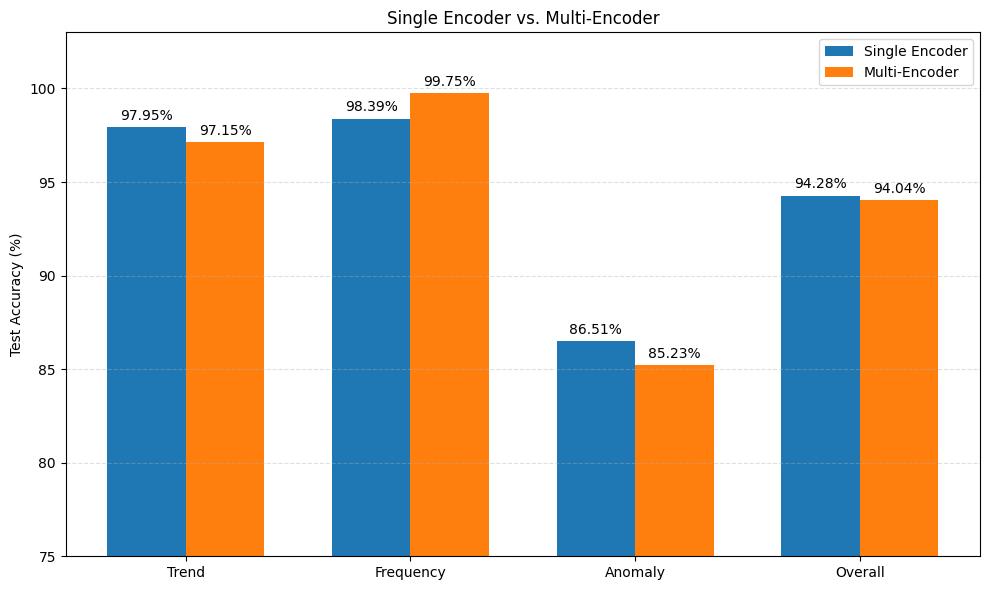

In [67]:
import matplotlib.pyplot as plt
import numpy as np

tasks = ["Trend", "Frequency", "Anomaly", "Overall"]
single = [97.95, 98.39, 86.51, 94.28]
multi = [97.15, 99.75, 85.23, 94.04]

x = np.arange(len(tasks))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, single, width, label="Single Encoder")
bars2 = ax.bar(x + width/2, multi, width, label="Multi-Encoder")

ax.set_ylabel("Test Accuracy (%)")
ax.set_title("Single Encoder vs. Multi-Encoder")
ax.set_xticks(x)
ax.set_xticklabels(tasks)
ax.set_ylim(75, 103)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("overall_accuracy_comparison.png", dpi=300)
plt.show()

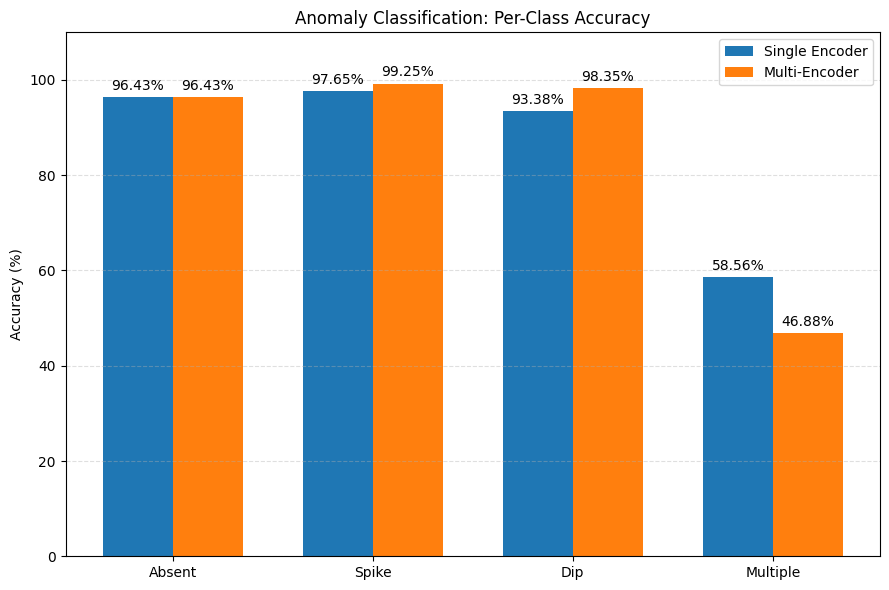

In [68]:
classes = ["Absent", "Spike", "Dip", "Multiple"]

single_anomaly = [96.43, 97.65, 93.38, 58.56]
multi_anomaly = [96.43, 99.25, 98.35, 46.88]

x = np.arange(len(classes))

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(x - width/2, single_anomaly, width, label="Single Encoder")
bars2 = ax.bar(x + width/2, multi_anomaly, width, label="Multi-Encoder")

ax.set_ylabel("Accuracy (%)")
ax.set_title("Anomaly Classification: Per-Class Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

ax.bar_label(bars1, fmt="%.2f%%", padding=3)
ax.bar_label(bars2, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("anomaly_per_class_comparison.png", dpi=300)
plt.show()

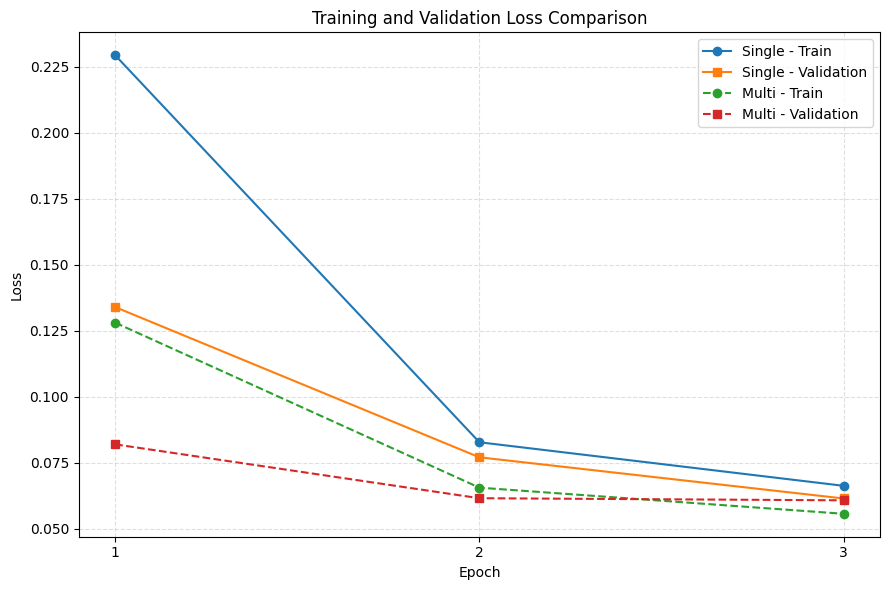

In [69]:
epochs = [1, 2, 3]

single_train = [0.2294, 0.0828, 0.0663]
single_val = [0.1340, 0.0771, 0.0615]

multi_train = [0.1281, 0.0656, 0.0557]
multi_val = [0.0820, 0.0616, 0.0608]

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(epochs, single_train, marker="o", label="Single - Train")
ax.plot(epochs, single_val, marker="s", label="Single - Validation")

ax.plot(epochs, multi_train, marker="o", linestyle="--", label="Multi - Train")
ax.plot(epochs, multi_val, marker="s", linestyle="--", label="Multi - Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training and Validation Loss Comparison")
ax.set_xticks(epochs)
ax.legend()
ax.grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("training_validation_loss.png", dpi=300)
plt.show()